# 08 v2: Cenários adversos no M4 Monthly (protocolo único v2)

**Fase 2b** da correção. O notebook 08 original foi mantido.

### Correções em relação ao NB08
| Item | NB08 | v2 |
|---|---|---|
| Previsão recursiva de RF, GB e SVR | deslocada em um passo (C1) | correta (próximo passo montado pela mesma função das linhas de treino) |
| Onde a perturbação é aplicada | série inteira, inclusive o teste (C2) | só no treino de cada janela, com estatísticas do próprio treino; teste sempre limpo |
| Linha de base | NB08, outro esquema de janelas e MAPE com fallback sMAPE | a da Fase 2a (mesmas séries, mesmas janelas) |
| ΔMAPE | só % relativo, rotulado como p.p. (C3) | % relativo **e** p.p. absolutos, mais a mediana das diferenças pareadas por série |
| Cenários | 6 executados (C 5% e truncamento nunca rodaram, C7) | os 9 |
| Truncamento | manteria o início da série, janelas diferentes da base (S1) | mantém a fração mais recente do treino de cada janela (mínimo 24 obs); teste igual ao da base |
| Modelos | 6 (sem sazonal ingênuo, média e SARIMA heurístico) | os 9 modelos rápidos |

**SARIMA automático**: fora dos cenários adversos pela mesma restrição operacional já documentada. No v2, com seleção de ordem por janela, a linha de base limpa levou 42 min (200 séries, 6 processos); os 9 cenários custariam cerca de 6 h e a análise suplementar mais 5 h.

**Análise suplementar "alvo ruidoso"** (rotulada, não oficial): perturba treino E teste da janela, reproduzindo a lógica do NB08 com as demais correções; serve para medir quanto da degradação reportada antes vinha de avaliar contra um alvo perturbado.

In [1]:
import sys, json, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

_root = Path.cwd().resolve()
PROJECT_ROOT = next(c for c in (_root, *_root.parents) if (c / 'src' / 'pipeline_v2.py').is_file())
sys.path.insert(0, str(PROJECT_ROOT))
from src import pipeline_v2 as pv

V2 = PROJECT_ROOT / 'results' / 'v2' / 'm4'
DIR_ADV = V2 / 'adversos'
DIR_ADV.mkdir(parents=True, exist_ok=True)
MODELOS = pv.MODELOS_RAPIDOS
NOMES = {'holt_winters': 'Holt-Winters', 'persistence': 'Persistência', 'ses': 'SES', 'gbt': 'Gradient Boosting',
         'sarima_heuristic': 'SARIMA heurístico', 'random_forest': 'Random Forest', 'seasonal_naive': 'Sazonal ingênuo',
         'svr': 'SVR', 'mean': 'Média histórica', 'sarima_auto': 'SARIMA automático'}
DESC = {c: v[2] for c, v in pv.CENARIOS.items()}

def carregar(pasta):
    arqs = sorted((V2 / pasta).glob('*_by_window.csv'))
    df = pd.concat([pd.read_csv(a) for a in arqs], ignore_index=True)
    return df[df['model'].isin(MODELOS)]

base = carregar('limpo')
adv = {c: carregar(c) for c in pv.CENARIOS}
ruid = {c: carregar(c + '_alvo_ruidoso') for c in pv.CENARIOS if pv.CENARIOS[c][0] != 'trunca'}
for c, d in adv.items():
    assert d.model.nunique() == len(MODELOS) and d.unique_id.nunique() == 200, c
print(f'Linha de base: {len(base):,} janelas | cenários: {len(adv)} | alvo ruidoso: {len(ruid)}')

Linha de base: 5,400 janelas | cenários: 9 | alvo ruidoso: 7


## 1. Continuidade operacional: status por cenário
Fallback = o modelo não conseguiu ajustar e usou o sazonal ingênuo ou a média (registrado). Erros e janelas inexistentes também aparecem aqui.

In [2]:
linhas = []
for c, d in [('limpo', base), *adv.items()]:
    t = pv.taxas_status(d)
    for m in MODELOS:
        linhas.append({'cenario': c, 'modelo': NOMES[m], 'OK (%)': 100 * t.loc[m, pv.OK],
                       'fallback (%)': 100 * (t.loc[m, pv.FB_SNAIVE] + t.loc[m, pv.FB_MEAN]),
                       'erro (%)': 100 * t.loc[m, pv.ERRO],
                       'explosivas (n)': int(pv.flag_explosiva(d[d.model == m]).sum())})
status = pd.DataFrame(linhas)
status.to_csv(DIR_ADV / 'm4_adversos_status.csv', index=False)
piv = status.pivot(index='cenario', columns='modelo', values='fallback (%)').round(1)
print('Fallback (% das janelas) por cenário e modelo:')
print(piv.to_string())
print('\nErros:', int((status['erro (%)'] > 0).sum()), 'combinações com erro | explosivas:',
      status.groupby('modelo')['explosivas (n)'].sum()[lambda s: s > 0].to_dict())

Fallback (% das janelas) por cenário e modelo:
modelo             Gradient Boosting  Holt-Winters  Média histórica  Persistência  Random Forest  SARIMA heurístico  SES  SVR  Sazonal ingênuo
cenario                                                                                                                                       
A_ruido_10pct                    0.0           0.0              0.0           0.0            0.0               33.3  0.0  0.0              0.0
A_ruido_30pct                    0.0           0.0              0.0           0.0            0.0               33.3  0.0  0.0              0.0
B_ausencias_10pct                0.0           0.0              0.0           0.0            0.0               33.3  0.0  0.5              0.0
B_ausencias_20pct                0.0           0.0              0.0           0.0            0.0               33.3  0.0  0.5              0.0
B_ausencias_30pct                0.0           0.0              0.0           0.0            0.

## 2. Tabela de degradação: ΔMAPE por modelo e cenário
Para cada cenário e modelo, nas mesmas 200 séries e janelas da linha de base:
- `delta_pct` = (MAPE_adv − MAPE_base) / MAPE_base × 100 (relativo, %);
- `delta_pp` = MAPE_adv − MAPE_base (absoluto, pontos percentuais);
- `delta_pp_pareado_mediana` = mediana, entre séries, de (MAPE_adv − MAPE_base) da mesma série.

Os MAPE são medianas entre séries das medianas por série (janelas com fallback incluídas, como na Tabela 3 v2).

In [3]:
bs_base = pv.agregar_por_serie(base)
deltas = []
for c, d in adv.items():
    t = pv.tabela_delta(bs_base, pv.agregar_por_serie(d)).reset_index()
    t['cenario'] = c
    deltas.append(t)
delta = pd.concat(deltas, ignore_index=True)
delta.to_csv(DIR_ADV / 'm4_adversos_delta_longo.csv', index=False)

def pivot(col):
    p = delta.pivot(index='cenario', columns='model', values=col).loc[list(pv.CENARIOS)]
    p.index = [DESC[c] for c in p.index]
    p.columns = [NOMES[m] for m in p.columns]
    return p[[NOMES[m] for m in MODELOS]]

d_pct, d_pp, d_par = pivot('delta_pct').round(1), pivot('delta_pp').round(2), pivot('delta_pp_pareado_mediana').round(2)
for nome, tab in [('ΔMAPE relativo (%)', d_pct), ('ΔMAPE absoluto (p.p.)', d_pp),
                  ('Mediana das diferenças pareadas por série (p.p.)', d_par)]:
    print(f'=== {nome} | positivo = degradação ===')
    print(tab.to_string()); print()
d_pct.to_csv(DIR_ADV / 'm4_adversos_delta_pct.csv')
d_pp.to_csv(DIR_ADV / 'm4_adversos_delta_pp.csv')
d_par.to_csv(DIR_ADV / 'm4_adversos_delta_pareado.csv')

=== ΔMAPE relativo (%) | positivo = degradação ===
                 Persistência  Média histórica  Sazonal ingênuo  SES  Holt-Winters  SARIMA heurístico  Random Forest  Gradient Boosting  SVR
Ruído σ=10%               0.1             -0.4              4.5 -3.8          -1.3                2.6            1.0                1.6 -0.4
Ruído σ=30%              13.3             -0.6             15.8  1.1          17.6               17.8            2.9               11.9  3.7
Ausências 10%             0.0             -0.7              0.9  0.0          -0.3                4.7           -6.4                0.6  1.3
Ausências 20%             1.2             -0.7              1.4  1.9           4.7                1.8            2.2                1.8 -4.5
Ausências 30%             2.5             -0.1              3.5  3.2          11.8               -2.7            3.9                5.2  7.8
Outliers 2%               0.5              0.2             24.0  6.6          13.1               19.0  

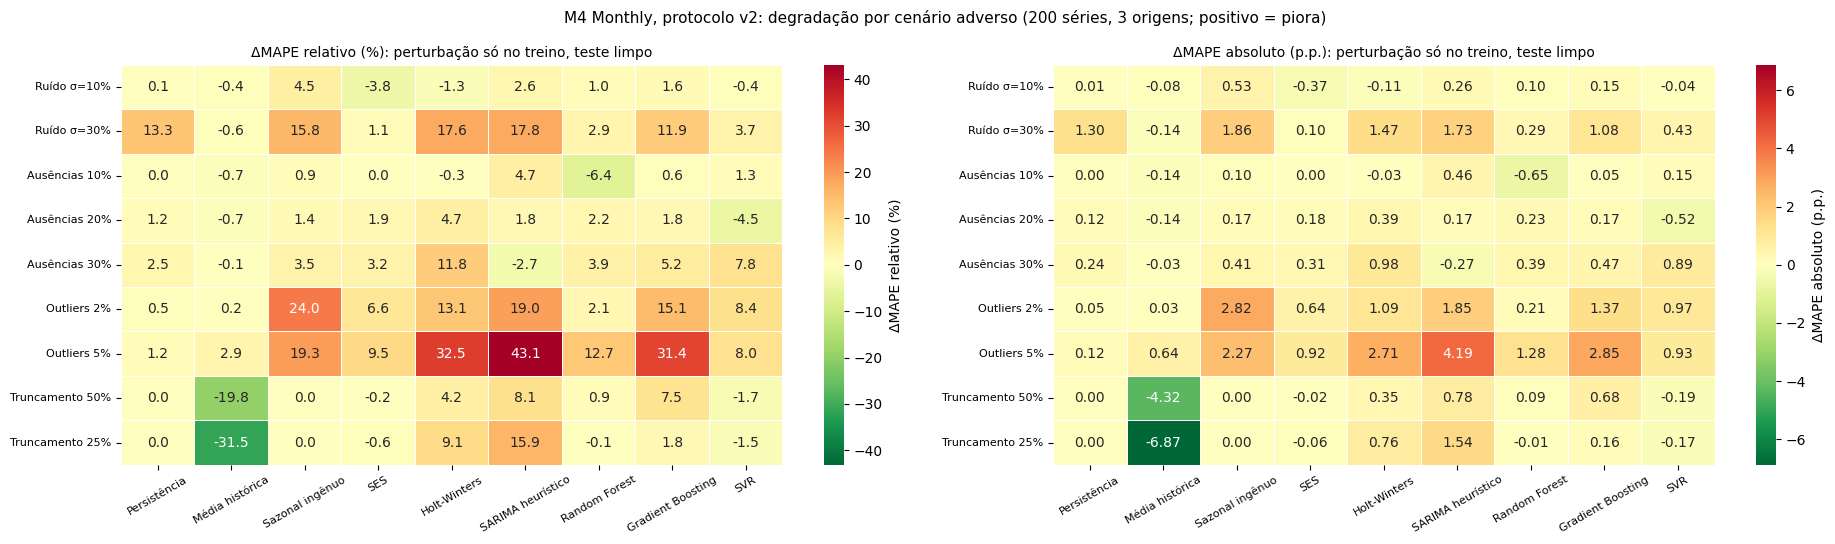

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(19, 5.5))
for ax, tab, titulo, fmt in [(axes[0], d_pct, 'ΔMAPE relativo (%)', '.1f'), (axes[1], d_pp, 'ΔMAPE absoluto (p.p.)', '.2f')]:
    lim = np.nanmax(np.abs(tab.values))
    sns.heatmap(tab, annot=True, fmt=fmt, cmap='RdYlGn_r', center=0, vmin=-lim, vmax=lim,
                linewidths=0.5, linecolor='white', ax=ax, cbar_kws={'label': titulo})
    ax.set_title(f'{titulo}: perturbação só no treino, teste limpo', fontsize=10)
    ax.set_xlabel(''); ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=30, labelsize=8); ax.tick_params(axis='y', rotation=0, labelsize=8)
fig.suptitle('M4 Monthly, protocolo v2: degradação por cenário adverso (200 séries, 3 origens; positivo = piora)', fontsize=11)
plt.tight_layout()
plt.savefig(DIR_ADV / 'fig_v2_m4_heatmap_delta.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Hierarquia de robustez
Por tipo de cenário, média do ΔMAPE relativo **com sinal** entre as intensidades (positivo = piora), e um escore geral (média de |Δ%| nos 9 cenários, como o `robustez_score` do NB08). Os **baselines triviais** (Persistência, Sazonal ingênuo, Média histórica) são ranqueados à parte: usam só os últimos valores ou a média, então sua "robustez" a truncamento e a perturbações fora do fim do treino é uma propriedade de construção, não comparável à dos modelos ajustados.

In [5]:
TIPO = {'ruido': 'Ruído', 'ausencia': 'Ausências', 'outlier': 'Outliers', 'trunca': 'Truncamento'}
delta['tipo'] = delta['cenario'].map(lambda c: TIPO[pv.CENARIOS[c][0]])
por_tipo = delta.pivot_table(index='model', columns='tipo', values='delta_pct', aggfunc='mean')[list(TIPO.values())]
por_tipo_pp = delta.pivot_table(index='model', columns='tipo', values='delta_pp', aggfunc='mean')[list(TIPO.values())]
escore = delta.groupby('model')['delta_pct'].apply(lambda x: x.abs().mean())
hier = por_tipo.round(1).add_suffix(' Δ%').join(por_tipo_pp.round(2).add_suffix(' Δp.p.'))
hier['Escore |Δ%| médio'] = escore.round(1)
hier['Rank robustez'] = escore.rank().astype(int)
TRIVIAIS = ['persistence', 'seasonal_naive', 'mean']
hier['Grupo'] = ['Baseline trivial' if m in TRIVIAIS else 'Modelo ajustado' for m in hier.index]
hier['Δ% médio (com sinal)'] = delta.groupby('model')['delta_pct'].mean().round(1)
hier['Rank robustez'] = hier.groupby('Grupo')['Escore |Δ%| médio'].rank(method='min').astype(int)
hier = hier.sort_values(['Grupo', 'Rank robustez'], ascending=[False, True])
hier.index = [NOMES[m] for m in hier.index]
for g, titulo in [('Modelo ajustado', 'Modelos ajustados'), ('Baseline trivial', 'Baselines triviais')]:
    print(f'=== {titulo} (rank dentro do grupo) ===')
    print(hier[hier['Grupo'] == g].drop(columns='Grupo').to_string()); print()
hier.to_csv(DIR_ADV / 'm4_adversos_hierarquia_robustez.csv')

=== Modelos ajustados (rank dentro do grupo) ===
tipo               Ruído Δ%  Ausências Δ%  Outliers Δ%  Truncamento Δ%  Ruído Δp.p.  Ausências Δp.p.  Outliers Δp.p.  Truncamento Δp.p.  Escore |Δ%| médio  Rank robustez  Δ% médio (com sinal)
SES                    -1.4           1.7          8.1            -0.4        -0.13             0.16            0.78              -0.04                3.0              1                   2.0
Random Forest           1.9          -0.1          7.4             0.4         0.19            -0.01            0.75               0.04                3.6              2                   2.1
SVR                     1.7           1.5          8.2            -1.6         0.19             0.18            0.95              -0.18                4.1              3                   2.4
Gradient Boosting       6.8           2.5         23.3             4.6         0.61             0.23            2.11               0.42                8.5              4              

## 3.1 Incerteza: IC de 95% por bootstrap pareado por série
2000 reamostragens das 200 séries (as mesmas séries sorteadas para a linha de base, para o cenário e para todos os modelos), estatística = diferença das medianas entre séries. Marcamos (i) os modelos cujo IC do Δ% inclui zero (degradação não distinguível de zero) e (ii) os pares de modelos cujo IC da diferença de Δ% inclui zero (não distinguíveis entre si no cenário).

In [6]:
bs_adv = {c: pv.agregar_por_serie(d) for c, d in adv.items()}
ics, pares = [], []
for c in pv.CENARIOS:
    tab, par = pv.bootstrap_delta(bs_base, bs_adv[c], MODELOS, n=2000)
    ics.append(tab.assign(cenario=c)); pares.append(par.assign(cenario=c))
ic = pd.concat(ics).reset_index().rename(columns={'index': 'model'})
par = pd.concat(pares, ignore_index=True)
ic.to_csv(DIR_ADV / 'm4_adversos_delta_ic95.csv', index=False)
par.to_csv(DIR_ADV / 'm4_adversos_pares_ic95.csv', index=False)

fmt = ic.assign(txt=lambda d: d.apply(lambda r: f"{r.delta_pct:+.1f} [{r.ic_pct_inf:+.1f}; {r.ic_pct_sup:+.1f}]"
                                       + (' ~0' if r.ic_inclui_zero else ''), axis=1))
tab_ic = fmt.pivot(index='cenario', columns='model', values='txt').loc[list(pv.CENARIOS), MODELOS]
tab_ic.index = [DESC[c] for c in tab_ic.index]; tab_ic.columns = [NOMES[m] for m in tab_ic.columns]
pd.set_option('display.width', 400); pd.set_option('display.max_colwidth', 40)
print('Δ% [IC 95%] por modelo e cenário; "~0" = IC inclui zero')
print(tab_ic.to_string()); print()
print(f'Combinações modelo x cenário com IC incluindo zero: {int(ic.ic_inclui_zero.sum())} de {len(ic)}')
print(f'Pares de modelos não distinguíveis (IC da diferença inclui zero): {int(par.ic_inclui_zero.sum())} de {len(par)}')
print()
print('Por cenário, pares não distinguíveis entre os modelos AJUSTADOS:')
aj = [m for m in MODELOS if m not in TRIVIAIS]
for c in pv.CENARIOS:
    s = par[(par.cenario == c) & par.modelo_a.isin(aj) & par.modelo_b.isin(aj) & par.ic_inclui_zero]
    print(f'  {DESC[c]:<16} {len(s):>2} de 15: ' + ', '.join(f'{NOMES[a]} = {NOMES[b]}' for a, b in zip(s.modelo_a, s.modelo_b)))

Δ% [IC 95%] por modelo e cenário; "~0" = IC inclui zero
                           Persistência       Média histórica        Sazonal ingênuo                    SES           Holt-Winters       SARIMA heurístico          Random Forest       Gradient Boosting                     SVR
Ruído σ=10%       +0.1 [-10.6; +4.4] ~0  -0.4 [-1.2; +1.5] ~0  +4.5 [-3.3; +10.7] ~0  -3.8 [-10.0; +3.2] ~0  -1.3 [-8.3; +16.0] ~0   +2.6 [-5.5; +14.2] ~0  +1.0 [-10.5; +7.5] ~0   +1.6 [-10.4; +8.9] ~0  -0.4 [-10.8; +13.6] ~0
Ruído σ=30%      +13.3 [-4.5; +22.2] ~0  -0.6 [-1.4; +2.9] ~0    +15.8 [+3.8; +26.6]  +1.1 [-6.8; +12.1] ~0    +17.6 [+2.5; +37.7]     +17.8 [+0.5; +31.9]  +2.9 [-6.4; +17.2] ~0  +11.9 [-0.3; +27.3] ~0   +3.7 [-6.6; +18.0] ~0
Ausências 10%      +0.0 [-6.0; +6.5] ~0  -0.7 [-3.0; +1.9] ~0   +0.9 [-4.4; +4.4] ~0   +0.0 [-5.3; +5.6] ~0  -0.3 [-5.0; +13.5] ~0   +4.7 [-9.5; +11.1] ~0   -6.4 [-9.5; +2.9] ~0   +0.6 [-5.1; +11.6] ~0   +1.3 [-4.8; +11.2] ~0
Ausências 20%      +1.2 [-7.3; +9.9] ~0 

## 4. Comparação com o NB08 antigo e com as Tabelas 4 e 5 da dissertação

### 4.1 ΔMAPE relativo antigo (NB08) x v2, nos 6 cenários que existiam

In [7]:
ANT2V2 = {'HoltWinters': 'holt_winters', 'SES': 'ses', 'Persistencia': 'persistence', 'GradientBoosting': 'gbt',
          'RandomForest': 'random_forest', 'SVR': 'svr'}
ant = pd.read_csv(PROJECT_ROOT / 'results' / 'adversos' / 'delta_mape_tabela.csv', index_col=0)
linhas = []
for desc in ant.index:
    for m_ant, m in ANT2V2.items():
        c = next(k for k, v in DESC.items() if v == desc)
        v2 = delta[(delta.cenario == c) & (delta.model == m)].iloc[0]
        linhas.append({'cenário': desc, 'modelo': NOMES[m], 'Δ% antigo (NB08)': ant.loc[desc, m_ant],
                       'Δ% v2': round(v2['delta_pct'], 1), 'Δp.p. v2': round(v2['delta_pp'], 2)})
comp = pd.DataFrame(linhas)
comp['mudança de sinal'] = np.where(np.sign(comp['Δ% antigo (NB08)']) != np.sign(comp['Δ% v2']), 'SIM', '')
print(comp.to_string(index=False))
comp.to_csv(DIR_ADV / 'comparacao_delta_nb08_v2.csv', index=False)

      cenário            modelo  Δ% antigo (NB08)  Δ% v2  Δp.p. v2 mudança de sinal
Ausências 10%      Holt-Winters               0.2   -0.3     -0.03              SIM
Ausências 10%               SES              -0.1    0.0      0.00              SIM
Ausências 10%      Persistência              -2.5    0.0      0.00              SIM
Ausências 10% Gradient Boosting              -4.2    0.6      0.05              SIM
Ausências 10%     Random Forest              -1.1   -6.4     -0.65                 
Ausências 10%               SVR               2.7    1.3      0.15                 
Ausências 20%      Holt-Winters               7.9    4.7      0.39                 
Ausências 20%               SES              -1.2    1.9      0.18              SIM
Ausências 20%      Persistência              -6.2    1.2      0.12              SIM
Ausências 20% Gradient Boosting              -7.9    1.8      0.17              SIM
Ausências 20%     Random Forest              -1.8    2.2      0.23          

### 4.2 Tabela 4 (colunas de robustez): categoria antiga x v2
> **Nota de transparência:** os limiares abaixo foram definidos **depois** de ver os resultados v2 (a primeira versão, por terços relativos, produzia rótulos contraditórios e foi descartada). Não são um critério pré-registrado.

A dissertação não explicita a regra das categorias. Para o v2 usamos limiares absolutos e declarados sobre a média do Δ% relativo de cada tipo de cenário:
- **Alta**: −2 < Δ% < 2 (degradação desprezível);
- **Moderada**: 2 <= Δ% < 10;
- **Baixa**: Δ% >= 10;
- **Melhora\***: Δ% <= −2 (efeito do pré-processamento ou do próprio cenário, não robustez intrínseca).

Os números ficam ao lado para permitir outra regra.

In [8]:
TAB4_ANT = {   # dissertação, Tabela 4: (ruído, ausências, outliers, truncamento)
    'holt_winters': ('Baixa', 'Baixa', 'Baixa', 'Neutro'), 'ses': ('Moderada', 'Moderada', 'Moderada', 'Neutro'),
    'sarima_heuristic': ('n.a.', 'n.a.', 'n.a.', 'Neutro'), 'gbt': ('Moderada', 'Elevada*', 'Moderada', 'Neutro'),
    'random_forest': ('Baixa', 'Elevada*', 'Moderada', 'Neutro'), 'svr': ('Baixa', 'Moderada', 'Alta', 'Neutro'),
    'persistence': ('Moderada', 'Elevada*', 'Moderada', 'Neutro'), 'seasonal_naive': ('n.a.', 'n.a.', 'n.a.', 'Neutro'),
    'mean': ('Alta', 'Alta', 'Alta', 'Neutro'),
}
def categorias(serie):
    return serie.map(lambda d: 'Melhora*' if d <= -2 else 'Alta' if d < 2 else 'Moderada' if d < 10 else 'Baixa')
cat_v2 = por_tipo.apply(categorias)
linhas = []
for m in MODELOS:
    lin = {'Modelo': NOMES[m]}
    for k, tipo in enumerate(TIPO.values()):
        lin[f'{tipo} antigo'] = TAB4_ANT[m][k]
        lin[f'{tipo} v2'] = f'{cat_v2.loc[m, tipo]} ({por_tipo.loc[m, tipo]:+.1f}%)'
    linhas.append(lin)
tab4 = pd.DataFrame(linhas).set_index('Modelo')
pd.set_option('display.width', 250)
print(tab4.to_string())
tab4.to_csv(DIR_ADV / 'comparacao_tabela4_robustez.csv')

                  Ruído antigo          Ruído v2 Ausências antigo      Ausências v2 Outliers antigo       Outliers v2 Truncamento antigo     Truncamento v2
Modelo                                                                                                                                                     
Persistência          Moderada  Moderada (+6.7%)         Elevada*      Alta (+1.2%)        Moderada      Alta (+0.9%)             Neutro       Alta (+0.0%)
Média histórica           Alta      Alta (-0.5%)             Alta      Alta (-0.5%)            Alta      Alta (+1.5%)             Neutro  Melhora* (-25.6%)
Sazonal ingênuo           n.a.    Baixa (+10.1%)             n.a.      Alta (+1.9%)            n.a.    Baixa (+21.6%)             Neutro       Alta (+0.0%)
SES                   Moderada      Alta (-1.4%)         Moderada      Alta (+1.7%)        Moderada  Moderada (+8.1%)             Neutro       Alta (-0.4%)
Holt-Winters             Baixa  Moderada (+8.2%)            Baix

### 4.3 Tabela 5: as recomendações ligadas a adversidade se sustentam?
Cada recomendação é transformada num critério verificável nos dados v2.

> **Nota de transparência:** os critérios foram formulados **depois** de ver os resultados v2, a partir da justificativa escrita na própria Tabela 5; não são pré-registrados. Diferenças pequenas entre modelos devem ser lidas junto com os IC da seção 3.1.

In [9]:
mape_adv = delta.pivot(index='cenario', columns='model', values='mape_adv')
tab3 = pd.read_csv(V2 / 'limpo' / 'tabela3_v2_m4.csv', index_col=0)
ML = ['random_forest', 'gbt', 'svr']
def menor(serie, modelos=None):
    s = serie if modelos is None else serie[modelos]
    return NOMES[s.idxmin()]
ruido_pct, out_pct = por_tipo['Ruído'], por_tipo['Outliers']
aus_mape = mape_adv.loc[['B_ausencias_10pct', 'B_ausencias_20pct', 'B_ausencias_30pct']].mean()
rec = [
    ('Dados limpos, sazonalidade regular → Holt-Winters', 'menor MAPE limpo (Tabela 3 v2)',
     tab3['MAPE (%)'].idxmin(), 'Holt-Winters'),
    ('Ruído esperado → SES', 'menor Δ% médio sob ruído (todos os modelos)', menor(ruido_pct), 'SES'),
    ('Outliers frequentes → SVR', 'menor Δ% médio sob outliers entre RF, GB e SVR', menor(out_pct, ML), 'SVR'),
    ('Ausências com interpolação → GB ou Persistência', 'menor MAPE mediano sob ausências (média de 10, 20 e 30%)',
     menor(aus_mape), 'Gradient Boosting ou Persistência'),
    ('Portfólio heterogêneo → SES como padrão', 'SES degrada menos que HW sob ruído e outliers (Δ p.p.)',
     'SES' if (por_tipo_pp.loc['ses', ['Ruído', 'Outliers']] < por_tipo_pp.loc['holt_winters', ['Ruído', 'Outliers']]).all()
     else 'Holt-Winters', 'SES'),
]
t5 = pd.DataFrame(rec, columns=['Recomendação (Tabela 5)', 'Critério verificável', 'Resultado v2', 'Esperado'])
t5['Sustenta?'] = [('SIM' if r in e.split(' ou ') else 'NÃO') for r, e in zip(t5['Resultado v2'], t5['Esperado'])]
print(t5.to_string(index=False))
print('\nApoio numérico: Δ% médio por tipo (ruído, outliers) e MAPE sob ausências')
print(pd.DataFrame({'Ruído Δ%': ruido_pct.round(1), 'Outliers Δ%': out_pct.round(1),
                    'Ruído Δp.p.': por_tipo_pp['Ruído'].round(2), 'Outliers Δp.p.': por_tipo_pp['Outliers'].round(2),
                    'MAPE sob ausências': aus_mape.round(2)}).rename(index=NOMES).sort_values('Ruído Δ%').to_string())
t5.to_csv(DIR_ADV / 'comparacao_tabela5_recomendacoes.csv', index=False)

                          Recomendação (Tabela 5)                                     Critério verificável  Resultado v2                          Esperado Sustenta?
Dados limpos, sazonalidade regular → Holt-Winters                           menor MAPE limpo (Tabela 3 v2)  Holt-Winters                      Holt-Winters       SIM
                             Ruído esperado → SES              menor Δ% médio sob ruído (todos os modelos)           SES                               SES       SIM
                        Outliers frequentes → SVR           menor Δ% médio sob outliers entre RF, GB e SVR Random Forest                               SVR       NÃO
  Ausências com interpolação → GB ou Persistência menor MAPE mediano sob ausências (média de 10, 20 e 30%)  Holt-Winters Gradient Boosting ou Persistência       NÃO
          Portfólio heterogêneo → SES como padrão   SES degrada menos que HW sob ruído e outliers (Δ p.p.)           SES                               SES       SIM

Apoio num

## 5. Análise suplementar (não oficial): "alvo ruidoso"
Mesmas perturbações aplicadas ao treino **e** ao teste de cada janela. A diferença em relação ao resultado oficial mede quanto da degradação vem de medir o erro contra um alvo perturbado (o que o NB08 fazia).

In [10]:
linhas = []
for c, d in ruid.items():
    t = pv.tabela_delta(bs_base, pv.agregar_por_serie(d))
    for m in MODELOS:
        of = delta[(delta.cenario == c) & (delta.model == m)].iloc[0]
        linhas.append({'cenário': DESC[c], 'modelo': NOMES[m], 'Δ% oficial (só treino)': round(of['delta_pct'], 1),
                       'Δ% alvo ruidoso': round(t.loc[m, 'delta_pct'], 1),
                       'diferença (p.p. de Δ%)': round(t.loc[m, 'delta_pct'] - of['delta_pct'], 1)})
sup = pd.DataFrame(linhas)
sup.to_csv(DIR_ADV / 'm4_adversos_suplementar_alvo_ruidoso.csv', index=False)
print(sup.pivot(index='cenário', columns='modelo', values='Δ% alvo ruidoso').loc[[DESC[c] for c in ruid]].round(1).to_string())
print('\nDiferença mediana (alvo ruidoso − oficial), por cenário:')
print(sup.groupby('cenário')['diferença (p.p. de Δ%)'].median().loc[[DESC[c] for c in ruid]].to_string())

modelo         Gradient Boosting  Holt-Winters  Média histórica  Persistência  Random Forest  SARIMA heurístico   SES   SVR  Sazonal ingênuo
cenário                                                                                                                                     
Ruído σ=10%                  8.4           4.4             -0.5          -0.4            0.8               13.5  -2.5  -0.8              6.9
Ruído σ=30%                 27.9          38.1              0.3          24.8           18.0               36.3  24.1   8.2             23.4
Ausências 10%                3.9          -6.0             -1.2          -0.9           -2.0               -0.9  -2.2  -1.6              2.8
Ausências 20%                5.3           5.0             -2.1          -2.3           -0.8                4.3  -1.6  -2.8              1.3
Ausências 30%                1.7          13.8              0.5           0.4            0.0                5.3   0.4   1.1              2.7
Outliers 2%  

## 6. Perfil de robustez por intensidade (equivalente à Fig. 16)

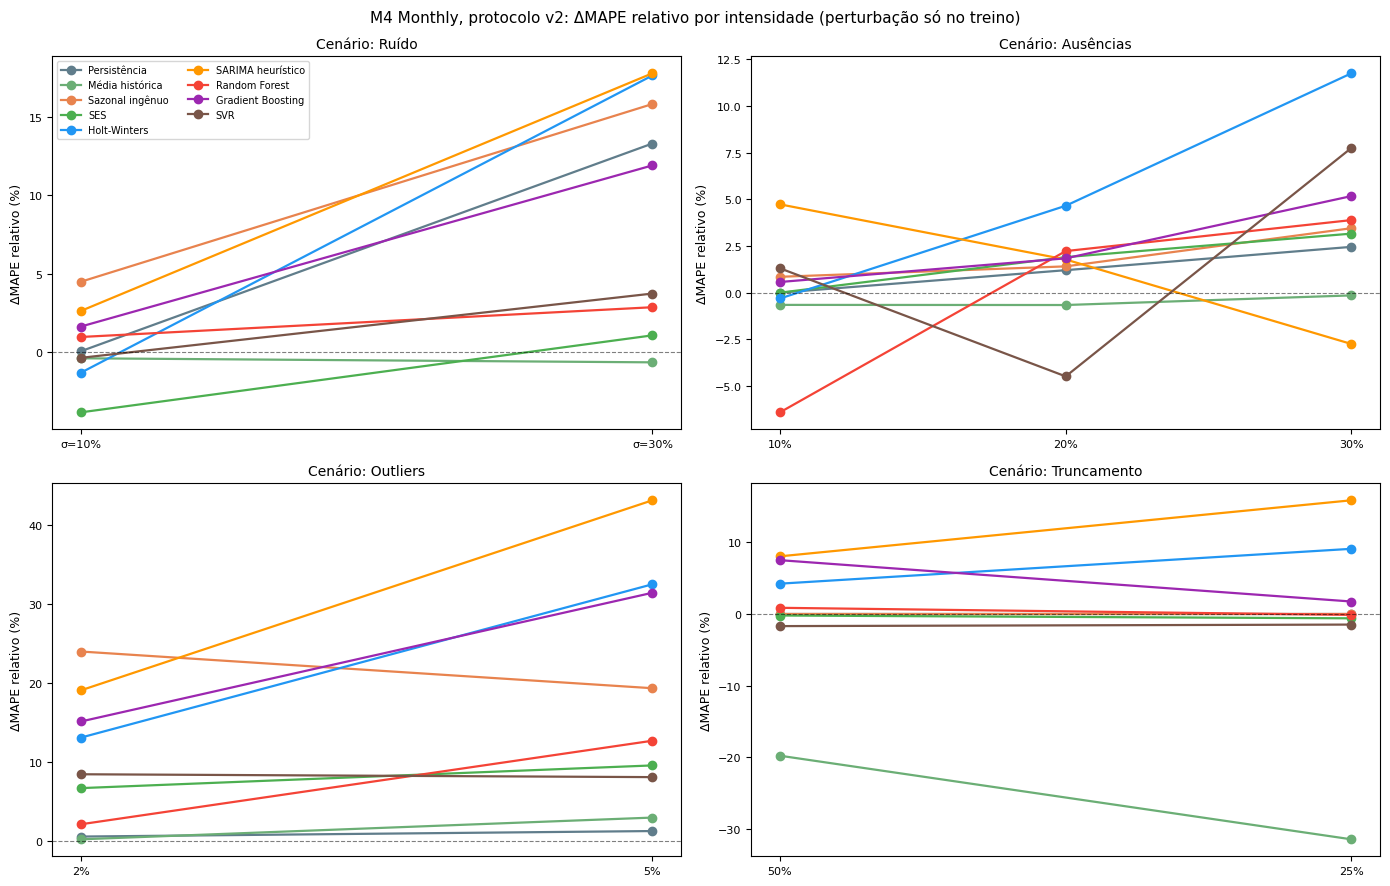

In [11]:
CORES = {'holt_winters': '#2196F3', 'ses': '#4CAF50', 'gbt': '#9C27B0', 'random_forest': '#F44336', 'svr': '#795548',
         'persistence': '#607D8B', 'seasonal_naive': '#E8834E', 'mean': '#6BAE75', 'sarima_heuristic': '#FF9800'}
prog = {'Ruído': ['A_ruido_10pct', 'A_ruido_30pct'], 'Ausências': ['B_ausencias_10pct', 'B_ausencias_20pct', 'B_ausencias_30pct'],
        'Outliers': ['C_outliers_2pct', 'C_outliers_5pct'], 'Truncamento': ['D_trunca_50pct', 'D_trunca_25pct']}
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (tipo, cs) in zip(axes.flatten(), prog.items()):
    for m in MODELOS:
        ys = [delta[(delta.cenario == c) & (delta.model == m)]['delta_pct'].iloc[0] for c in cs]
        ax.plot([DESC[c].split()[-1] for c in cs], ys, marker='o', color=CORES[m], label=NOMES[m], linewidth=1.6)
    ax.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
    ax.set_title(f'Cenário: {tipo}', fontsize=10); ax.set_ylabel('ΔMAPE relativo (%)', fontsize=9)
    ax.tick_params(labelsize=8)
axes[0, 0].legend(fontsize=7, ncol=2)
fig.suptitle('M4 Monthly, protocolo v2: ΔMAPE relativo por intensidade (perturbação só no treino)', fontsize=11)
plt.tight_layout()
plt.savefig(DIR_ADV / 'fig_v2_m4_perfil_robustez.png', dpi=150, bbox_inches='tight')
plt.show()